# 05 - Diagnostics

Five checks behind the modelling choices:

1. **Within / between decomposition** of the static regression coefficients,
   splitting each regressor's variation into a high-frequency (within a rolling
   window) and a low-frequency (across windows) part, to show that the pooled
   OLS coefficient mixes two different time scales.
2. **Augmented Dickey-Fuller (ADF)** tests, to gauge the persistence of each
   series (a strong low-frequency relationship on a highly persistent regressor
   carries spurious-regression risk).
3. **Variance inflation factors**, for collinearity among the regressors.
4. **Innovation diagnostics** for the DLM: autocorrelation, volatility clustering
   and normality of the one-step-ahead forecast errors.
5. **The choice of $\lambda$**: how the coefficient paths and the joint deviation
   change with it, and what the likelihood says.

Sections 1 to 3 only report statistics. Sections 4 and 5 come with a short reading,
because they bear directly on how far the DLM results can be pushed.

## Setup

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller

import safe_haven as sh
from safe_haven import CURRENCIES, REGRESSORS, FIG_DIR, PAPER_DIR

WINDOW = 252            # 1-year rolling window

## Load and construct variables

Same construction as notebooks 02-04, from the shared `safe_haven.py`.

In [2]:
data = sh.load_data()
model_frame = data.model_frame
excess, fx_vol = data.excess, data.fx_vol
sp500_d, ust10y_d, ted, vix_d = data.sp500_d, data.ust10y_d, data.ted, data.vix_d

## 1. Within / between decomposition

For each currency: the pooled OLS coefficient (**FULL**), the coefficient from
deviations around a 1-year rolling mean (**WITHIN**, high-frequency), and the
coefficient from the rolling means themselves (**BETWEEN**, low-frequency).

In [3]:
def within_between(cur):
    df = model_frame(cur)
    cols = ["excess"] + REGRESSORS
    lo = df[cols].rolling(WINDOW).mean().dropna()
    hi = (df[cols] - df[cols].rolling(WINDOW).mean()).dropna()
    full = sm.OLS(df["excess"], sm.add_constant(df[REGRESSORS])).fit().params
    within = sm.OLS(hi["excess"], sm.add_constant(hi[REGRESSORS])).fit().params
    between = sm.OLS(lo["excess"], sm.add_constant(lo[REGRESSORS])).fit().params
    return pd.DataFrame({"FULL": full[REGRESSORS],
                         "WITHIN": within[REGRESSORS],
                         "BETWEEN": between[REGRESSORS]}).round(3)

wb = pd.concat({cur: within_between(cur) for cur in CURRENCIES}, axis=1)
wb

CHF                   EUR                   GBP                 \
         FULL WITHIN BETWEEN   FULL WITHIN BETWEEN   FULL WITHIN BETWEEN   
SP500   0.030  0.028   0.124  0.068  0.069   0.166  0.085  0.087   0.265   
UST10Y -0.022 -0.021  -0.040 -0.013 -0.012  -0.032 -0.008 -0.008  -0.035   
fxvol   0.000  0.000   0.001  0.000  0.000   0.000  0.000  0.000   0.000   
TED    -0.066 -0.152  -0.065 -0.084 -0.231  -0.011 -0.215 -0.357  -0.094   
VIX     0.004  0.004   0.037  0.002  0.002   0.020  0.000  0.000   0.018   

          JPY                 
         FULL WITHIN BETWEEN  
SP500  -0.009 -0.016   0.162  
UST10Y -0.035 -0.036  -0.062  
fxvol   0.001  0.000   0.001  
TED     0.119  0.118   0.091  
VIX     0.009  0.008   0.027

### Low-frequency variance share

Share of each regressor's variance carried by the 1-year rolling mean, a simple
persistence gauge. A near-zero share means the regressor is essentially
high-frequency; a large share means it is dominated by slow movements.

In [4]:
def lowfreq_share(cur):
    df = model_frame(cur)
    out = {}
    for r in REGRESSORS:
        s = df[r]
        lo = s.rolling(WINDOW).mean()
        out[r] = lo.var() / s.loc[lo.dropna().index].var()
    return pd.Series(out)

share = pd.DataFrame({cur: lowfreq_share(cur) for cur in CURRENCIES}).round(3)
share

,CHF,EUR,GBP,JPY
SP500,0.003,0.003,0.003,0.003
UST10Y,0.003,0.003,0.003,0.003
fxvol,0.556,0.542,0.610,0.555
TED,0.620,0.620,0.620,0.616
VIX,0.001,0.001,0.001,0.001


## 2. ADF stationarity tests

Augmented Dickey-Fuller test (H0: unit root / non-stationary). A small p-value
rejects the unit root, i.e. indicates stationarity. Tested for the excess
returns, the per-currency fx volatility, and the shared regressors.

In [5]:
def adf_row(name, s):
    stat, p, *_ = adfuller(s.dropna(), autolag="AIC")
    return {"series": name, "ADF": round(stat, 2), "p-value": round(p, 4),
            "stationary@5%": p < 0.05}

rows = []
for cur in CURRENCIES:
    rows.append(adf_row(f"excess_{cur}", excess[cur]))
for cur in CURRENCIES:
    rows.append(adf_row(f"fxvol_{cur}", fx_vol[cur]))
for name, s in [("SP500", sp500_d), ("VIX", vix_d), ("UST10Y", ust10y_d), ("TED", ted)]:
    rows.append(adf_row(name, s))

adf = pd.DataFrame(rows).set_index("series")
adf

,ADF,p-value,stationary@5%
series,,,
excess_CHF,-17.56,0.0000,True
excess_EUR,-35.25,0.0000,True
excess_GBP,-17.14,0.0000,True
excess_JPY,-54.20,0.0000,True
fxvol_CHF,-4.10,0.0010,True
fxvol_EUR,-4.11,0.0009,True
fxvol_GBP,-3.93,0.0018,True
fxvol_JPY,-3.97,0.0016,True
SP500,-14.39,0.0000,True


## 3. Multicollinearity (VIF)

Variance inflation factor per regressor (computed per currency, since fx
volatility is currency-specific). Common thresholds: VIF > 5 (moderate) or
> 10 (severe) signal problematic collinearity.

In [6]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def vif(cur):
    X = sm.add_constant(model_frame(cur)[REGRESSORS]).values
    return pd.Series(
        {REGRESSORS[i - 1]: variance_inflation_factor(X, i) for i in range(1, X.shape[1])})

vif_table = pd.DataFrame({cur: vif(cur) for cur in CURRENCIES}).round(2)
vif_table

,CHF,EUR,GBP,JPY
SP500,2.24,2.24,2.24,2.25
UST10Y,1.10,1.10,1.10,1.10
fxvol,1.16,1.16,1.13,1.10
TED,1.16,1.16,1.13,1.11
VIX,2.16,2.16,2.16,2.16


## 4. DLM innovation diagnostics

If the DLM is well specified, the standardized one-step-ahead forecast errors
(innovations $e_t$) should be white noise and standard normal. Three checks:
**Ljung-Box** on the innovations (H0: no autocorrelation up to lag 10),
Ljung-Box on the **squared** innovations (H0: no autocorrelation in the
variance, i.e. no volatility clustering), and **Jarque-Bera** (H0: normal).
The DLM is refitted here as in notebook 04.

In [7]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats

def fit_dlm(cur, lam=sh.LAMBDA):
    df = model_frame(cur)
    res, _ = sh.dlm_fit(df, lam)
    return df, res

rows = []
for cur in CURRENCIES:
    _, res = fit_dlm(cur)
    e = pd.Series(res.standardized_forecasts_error[0]).replace([np.inf, -np.inf], np.nan).dropna()
    rows.append({
        "currency": cur,
        "Ljung-Box(10) p": round(acorr_ljungbox(e, lags=[10])["lb_pvalue"].iloc[0], 4),
        "Ljung-Box(10) p, squared": f"{acorr_ljungbox(e ** 2, lags=[10])['lb_pvalue'].iloc[0]:.2g}",
        "Jarque-Bera p": f"{stats.jarque_bera(e)[1]:.2g}",
    })
innovation = pd.DataFrame(rows).set_index("currency")
innovation

,Ljung-Box(10) p,"Ljung-Box(10) p, squared",Jarque-Bera p
currency,,,
CHF,0.0294,6.9e-27,0
EUR,0.3632,6.2e-148,0
GBP,0.0017,2.2e-114,0
JPY,0.0002,2.6e-44,0


Jarque-Bera rejects normality for all four currencies, and Ljung-Box on the squared innovations rejects just as clearly: the errors are heavy-tailed and their variance clusters. The innovations themselves are less of a problem. Some autocorrelation is left for CHF, GBP and JPY at the 5% level, none for the EUR. A constant-variance Gaussian observation equation cannot capture the first two features, which is the argument for the stochastic-volatility extension in `ROADMAP.md`.

## 5. The choice of $\lambda$

$\lambda$ is fixed at $10^{-3}$ throughout. Three things are checked here: how the
two coefficients that move most look under a smaller and a larger value, how the
joint deviation of notebook 04 changes, and where the likelihood would put
$\lambda$ if asked.

### Coefficient paths under different $\lambda$

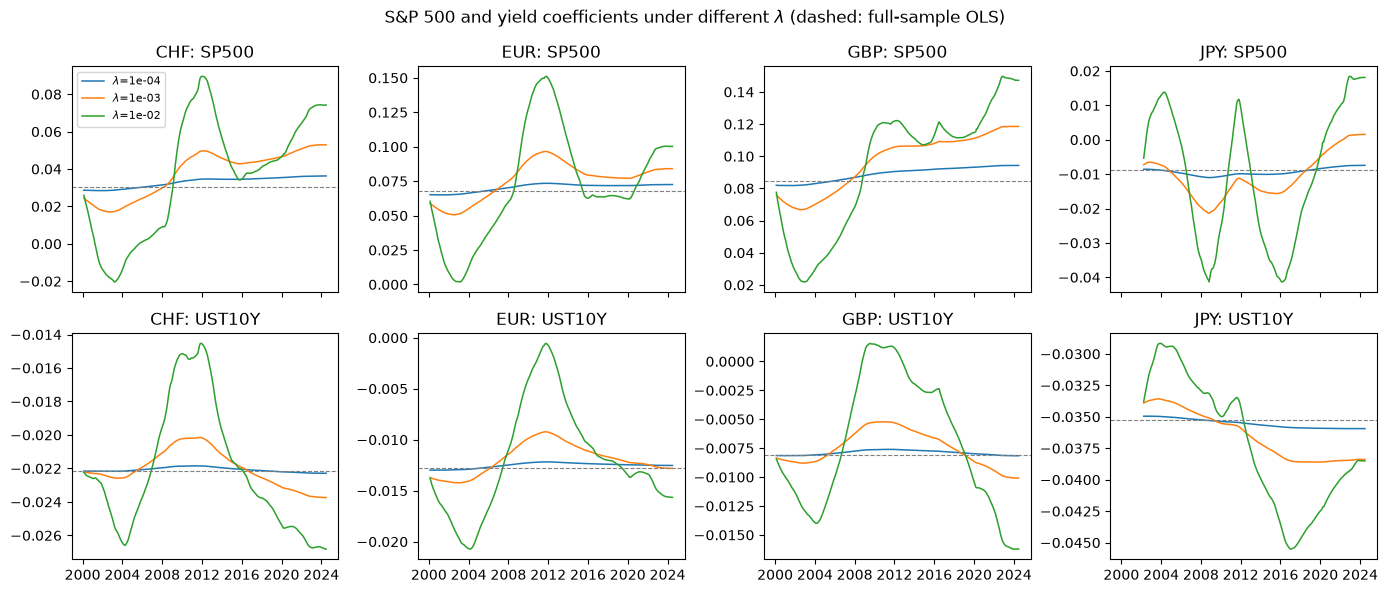

In [8]:
import matplotlib.pyplot as plt
from scipy.stats import chi2

LAMBDAS = [1e-4, 1e-3, 1e-2]
SHOW = ["SP500", "UST10Y"]
TERMS = ["const"] + REGRESSORS
threshold = chi2.ppf(0.95, len(TERMS))

fig, axes = plt.subplots(len(SHOW), 4, figsize=(14, 6), sharex=True)
sens = {}
for col, cur in enumerate(CURRENCIES):
    df = model_frame(cur)
    for lam in LAMBDAS:
        res, ols = sh.dlm_fit(df, lam)
        D = pd.Series(sh.joint_deviation(res, ols.params), index=df.index)
        sens[(cur, lam)] = {"max D_t": D.max(), "peak": D.idxmax().date(),
                            "days above 95% line": int((D > threshold).sum())}
        for row, coef in enumerate(SHOW):
            axes[row, col].plot(df.index, res.smoothed_state[TERMS.index(coef)], lw=1.1,
                                label=fr"$\lambda$={lam:.0e}")
    for row, coef in enumerate(SHOW):
        axes[row, col].axhline(ols.params[TERMS.index(coef)], color="grey", ls="--", lw=0.8)
        axes[row, col].set_title(f"{cur}: {coef}")
axes[0, 0].legend(fontsize=8)
fig.suptitle(r"S&P 500 and yield coefficients under different $\lambda$ (dashed: full-sample OLS)")
fig.tight_layout()

FIG_DIR.mkdir(exist_ok=True)
fig.savefig(FIG_DIR / "dlm_lambda_sensitivity.png", dpi=300, bbox_inches="tight")
plt.show()

### Joint deviation under different $\lambda$

The maximum of the joint deviation $D_t$ from notebook 04, the day it peaks, and the number of days it spends above the 95% $\chi^2_6$ line (12.59).

In [9]:
sens_table = pd.DataFrame(sens).T
sens_table.index.names = ["currency", "lambda"]
sens_table["max D_t"] = sens_table["max D_t"].astype(float).round(1)
sens_table.to_csv(sh.DATA_DIR / "lambda_sensitivity.csv")
sens_table

max D_t        peak days above 95% line
currency lambda                                         
CHF      0.0001      0.9  2011-12-20                   0
         0.0010      8.6  2011-11-01                   0
         0.0100     36.0  2011-11-01                1228
EUR      0.0001      2.6  2011-09-09                   0
         0.0010     27.2  2011-07-21                 961
         0.0100     91.5  2011-09-09                2210
GBP      0.0001      2.9  2022-09-23                   0
         0.0010     12.0  2011-10-03                   0
         0.0100     37.5  2002-08-23                2872
JPY      0.0001      0.4  2023-01-12                   0
         0.0010      5.1  2022-11-10                   0
         0.0100     18.1  2016-06-24                 568

### What the likelihood says

The log-likelihood as a function of $\lambda$, with $V$ re-estimated at each value. For this comparison the filter does not start from the OLS estimate: the initial state is vague and the first 250 days are left out of the likelihood (see `safe_haven.dlm_profile`). Plotted relative to the value at $\lambda = 10^{-3}$.

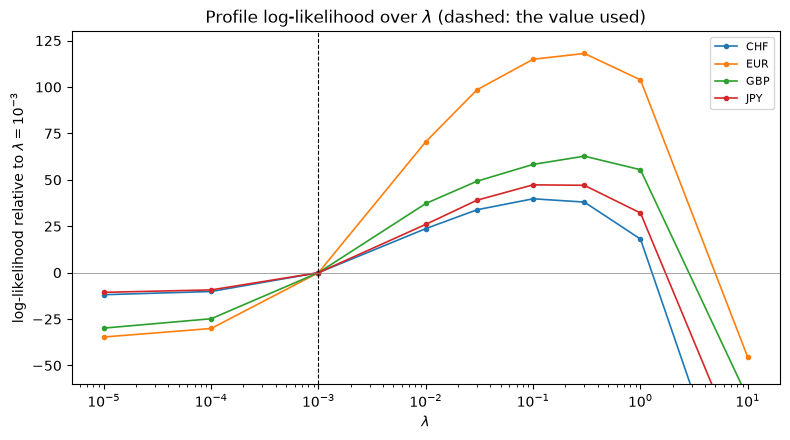

,CHF,EUR,GBP,JPY
lambda,,,,
0.00001,-11.9,-34.7,-29.9,-10.6
0.00010,-10.1,-30.1,-24.8,-9.3
0.00100,0.0,0.0,0.0,0.0
0.01000,23.7,70.5,37.3,26.0
0.03000,33.9,98.5,49.3,39.0
0.10000,39.8,115.0,58.3,47.3
0.30000,38.0,118.1,62.8,47.1
1.00000,18.1,103.9,55.5,32.1
10.00000,-150.2,-45.6,-67.6,-106.6


In [10]:
GRID = [1e-5, 1e-4, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1, 10]
profile = pd.DataFrame({cur: sh.dlm_profile(model_frame(cur), GRID) for cur in CURRENCIES})
profile.index.name = "lambda"
relative = profile - profile.loc[1e-3]
relative.round(1).to_csv(sh.DATA_DIR / "lambda_profile.csv")

fig, ax = plt.subplots(figsize=(8, 4.5))
for cur in CURRENCIES:
    ax.plot(relative.index, relative[cur], marker="o", ms=3, lw=1.2, label=cur)
ax.axvline(1e-3, color="black", ls="--", lw=0.8)
ax.axhline(0, color="grey", lw=0.5)
ax.set_xscale("log")
ax.set_ylim(-60, 130)
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel(r"log-likelihood relative to $\lambda = 10^{-3}$")
ax.set_title(r"Profile log-likelihood over $\lambda$ (dashed: the value used)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "dlm_lambda_profile.png", dpi=300, bbox_inches="tight")
plt.show()

relative.round(1)

Two things stand out.

First, the reading of notebook 04 depends on $\lambda$. At $10^{-3}$ only the EUR's joint deviation crosses the 95% line. At $10^{-2}$ all four do, at $10^{-4}$ none does. The timing holds up better than the size: for CHF and EUR the peak stays in the second half of 2011 under all three values. For GBP and JPY it moves around.

Second, the likelihood does not ask for less time variation. The profile peaks at a $\lambda$ between 0.1 and 0.3 for all four currencies, more than a hundred times the value used here, and the gain over $10^{-3}$ is large (about 40 log points for the CHF, 118 for the EUR). So the fixed value is not where the data would put it.

I keep it anyway, for one reason. With a constant $V$ the coefficients are the only place where the model can put volatility clustering (section 4), and leaving out stochastic volatility is a known way to overstate coefficient drift: Sims (2001) made exactly this point against Cogley and Sargent, whose 2005 paper added stochastic volatility in response. An estimate of $\lambda$ from this model could well be too large. $10^{-3}$ is therefore a deliberately tight prior. It shows the slow movements and little else, and everything in notebook 04 should be read as conditional on it.

## Export tables to LaTeX

Write the diagnostics tables (within/between, ADF, VIF, DLM innovations) to
`../paper/` for inclusion in the paper via `\input{}`.

In [11]:
PAPER = PAPER_DIR; PAPER.mkdir(exist_ok=True)

def _esc(s): return str(s).replace("_", r"\_")
def _tbl(caption, label, header, rows, align):
    return "\n".join([r"\begin{table}[H]", r"\centering", rf"\caption{{{caption}}}",
        rf"\label{{{label}}}", rf"\begin{{tabular}}{{{align}}}", r"\toprule",
        header + r" \\", r"\midrule"] + rows + [r"\bottomrule", r"\end{tabular}", r"\end{table}"])

wb_rows = []
for cur in CURRENCIES:
    d = within_between(cur)
    for reg in REGRESSORS:
        wb_rows.append(f"{cur} & {reg} & ${d.loc[reg,'FULL']:.3f}$ & "
                       f"${d.loc[reg,'WITHIN']:.3f}$ & ${d.loc[reg,'BETWEEN']:.3f}$ " + r"\\")
    if cur != CURRENCIES[-1]: wb_rows.append(r"\midrule")
(PAPER/"withinbetween.tex").write_text(_tbl(
    "Within/between decomposition of the static coefficients. FULL = pooled OLS; "
    "WITHIN = deviations from a 1-year rolling mean; BETWEEN = rolling means.",
    "tab:withinbetween", "Currency & Regressor & FULL & WITHIN & BETWEEN", wb_rows, "llrrr"))

adf_rows = [f"{_esc(n)} & ${row['ADF']:.2f}$ & ${row['p-value']:.3f}$ & "
            f"{'yes' if row['stationary@5%'] else 'no'} " + r"\\" for n, row in adf.iterrows()]
(PAPER/"adf.tex").write_text(_tbl(
    "Augmented Dickey-Fuller tests (H0: unit root). Small $p$ indicates stationarity.",
    "tab:adf", r"Series & ADF & $p$-value & Stationary (5\%)", adf_rows, "lrrl"))

vif_rows = [f"{reg} & " + " & ".join(f"${vif_table.loc[reg,cur]:.2f}$" for cur in CURRENCIES) + r" \\"
            for reg in REGRESSORS]
(PAPER/"vif.tex").write_text(_tbl(
    "Variance inflation factors (per currency). Values below 5 indicate no problematic collinearity.",
    "tab:vif", "Regressor & " + " & ".join(CURRENCIES), vif_rows, "lrrrr"))

inn_rows = [f"{cur} & ${_esc(row.iloc[0])}$ & ${_esc(row.iloc[1])}$ & ${_esc(row.iloc[2])}$ " + r"\\"
            for cur, row in innovation.iterrows()]
(PAPER/"innovations.tex").write_text(_tbl(
    r"DLM innovation diagnostics: $p$-values of Ljung-Box (lag 10) on the standardized "
    r"one-step-ahead forecast errors and on their squares, and of Jarque-Bera.",
    "tab:innovations", r"Currency & Ljung-Box $p$ & Ljung-Box $p$ (squared) & Jarque-Bera $p$",
    inn_rows, "lrrr"))
print("Wrote diagnostics tables to paper/")

Wrote diagnostics tables to paper/
